# Public data experiments
This is the notebook to run the public data experiment

In [1]:
import sys
from pathlib import Path

# Add the workspace root to sys.path
workspace_root = Path("/Users/eduardohome/workspace/benchmark_credit_scoring")
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))

# Now you can import from src
from src.utils.csv_config import read_csv_by_name, create_imbalanced_datasets, merge_xai_results
from src.model.functions import save_model, load_model, get_split_data
from src.xai.functions import get_train_iterations_shap, compute_xai_metrics_from_shap
from src.graph.functions import plot_model_boxplot, plot_imbalance_boxplot_grid, load_xai_file, plot_models_by_imbalance

try:
    from src.model.functions import get_train_model
except Exception as exc:
    # provide helpful message if import fails
    print("Failed to import model utilities:", exc)
    print("This often means a missing dependency such as libomp for LightGBM.")
    print("On macOS you can install it with `brew install libomp` and then restart the kernel.")
    raise

# General imports
import pandas as pd
from pathlib import Path

In [2]:
# -------------------------
# Settings
# -------------------------
data_dir = Path("/Users/eduardohome/workspace/benchmark_credit_scoring/data")
#datasets_to_run = ["australian", "german", "japan", "kgccdea", "taiwan", "th02", "kggmsc"]
datasets_to_run = ["australian", "german", "japan", "kgccdea", "th02"]
target_col = "target"

# Edit this list whenever you want more/less imbalance datasets
imbalance_levels = [10, 15, 20, 25]
n_iterations = 100
percentage = 90

# list of estimators understood by functions.get_model
model_choices = ["XGBoost", "LightGBM", "RandomForest", "BoostDT", "BoostSGB", "BagNN", "ANN"]
product = "default"

## Read data - Local Interpretability metrics

In [3]:
df_local = load_xai_file(
    data_dir=data_dir,
    dataset_name=datasets_to_run,
    file_type="all_models_resume_local",
)
df_local

,index,rankstab_local,rankstab_local_weight,dataset,imbalance,model
0,1,0.313662,0.110273,australian,10,XGBoost
1,2,0.299365,0.111697,australian,10,XGBoost
2,5,0.321101,0.110010,australian,10,XGBoost
3,10,0.279712,0.093580,australian,10,XGBoost
4,11,0.320741,0.110059,australian,10,XGBoost
...,...,...,...,...,...,...
55819,1189,0.384207,0.153177,th02,25,ANN
55820,1191,0.333856,0.122401,th02,25,ANN
55821,1195,0.490744,0.199409,th02,25,ANN
55822,1198,0.327609,0.111915,th02,25,ANN


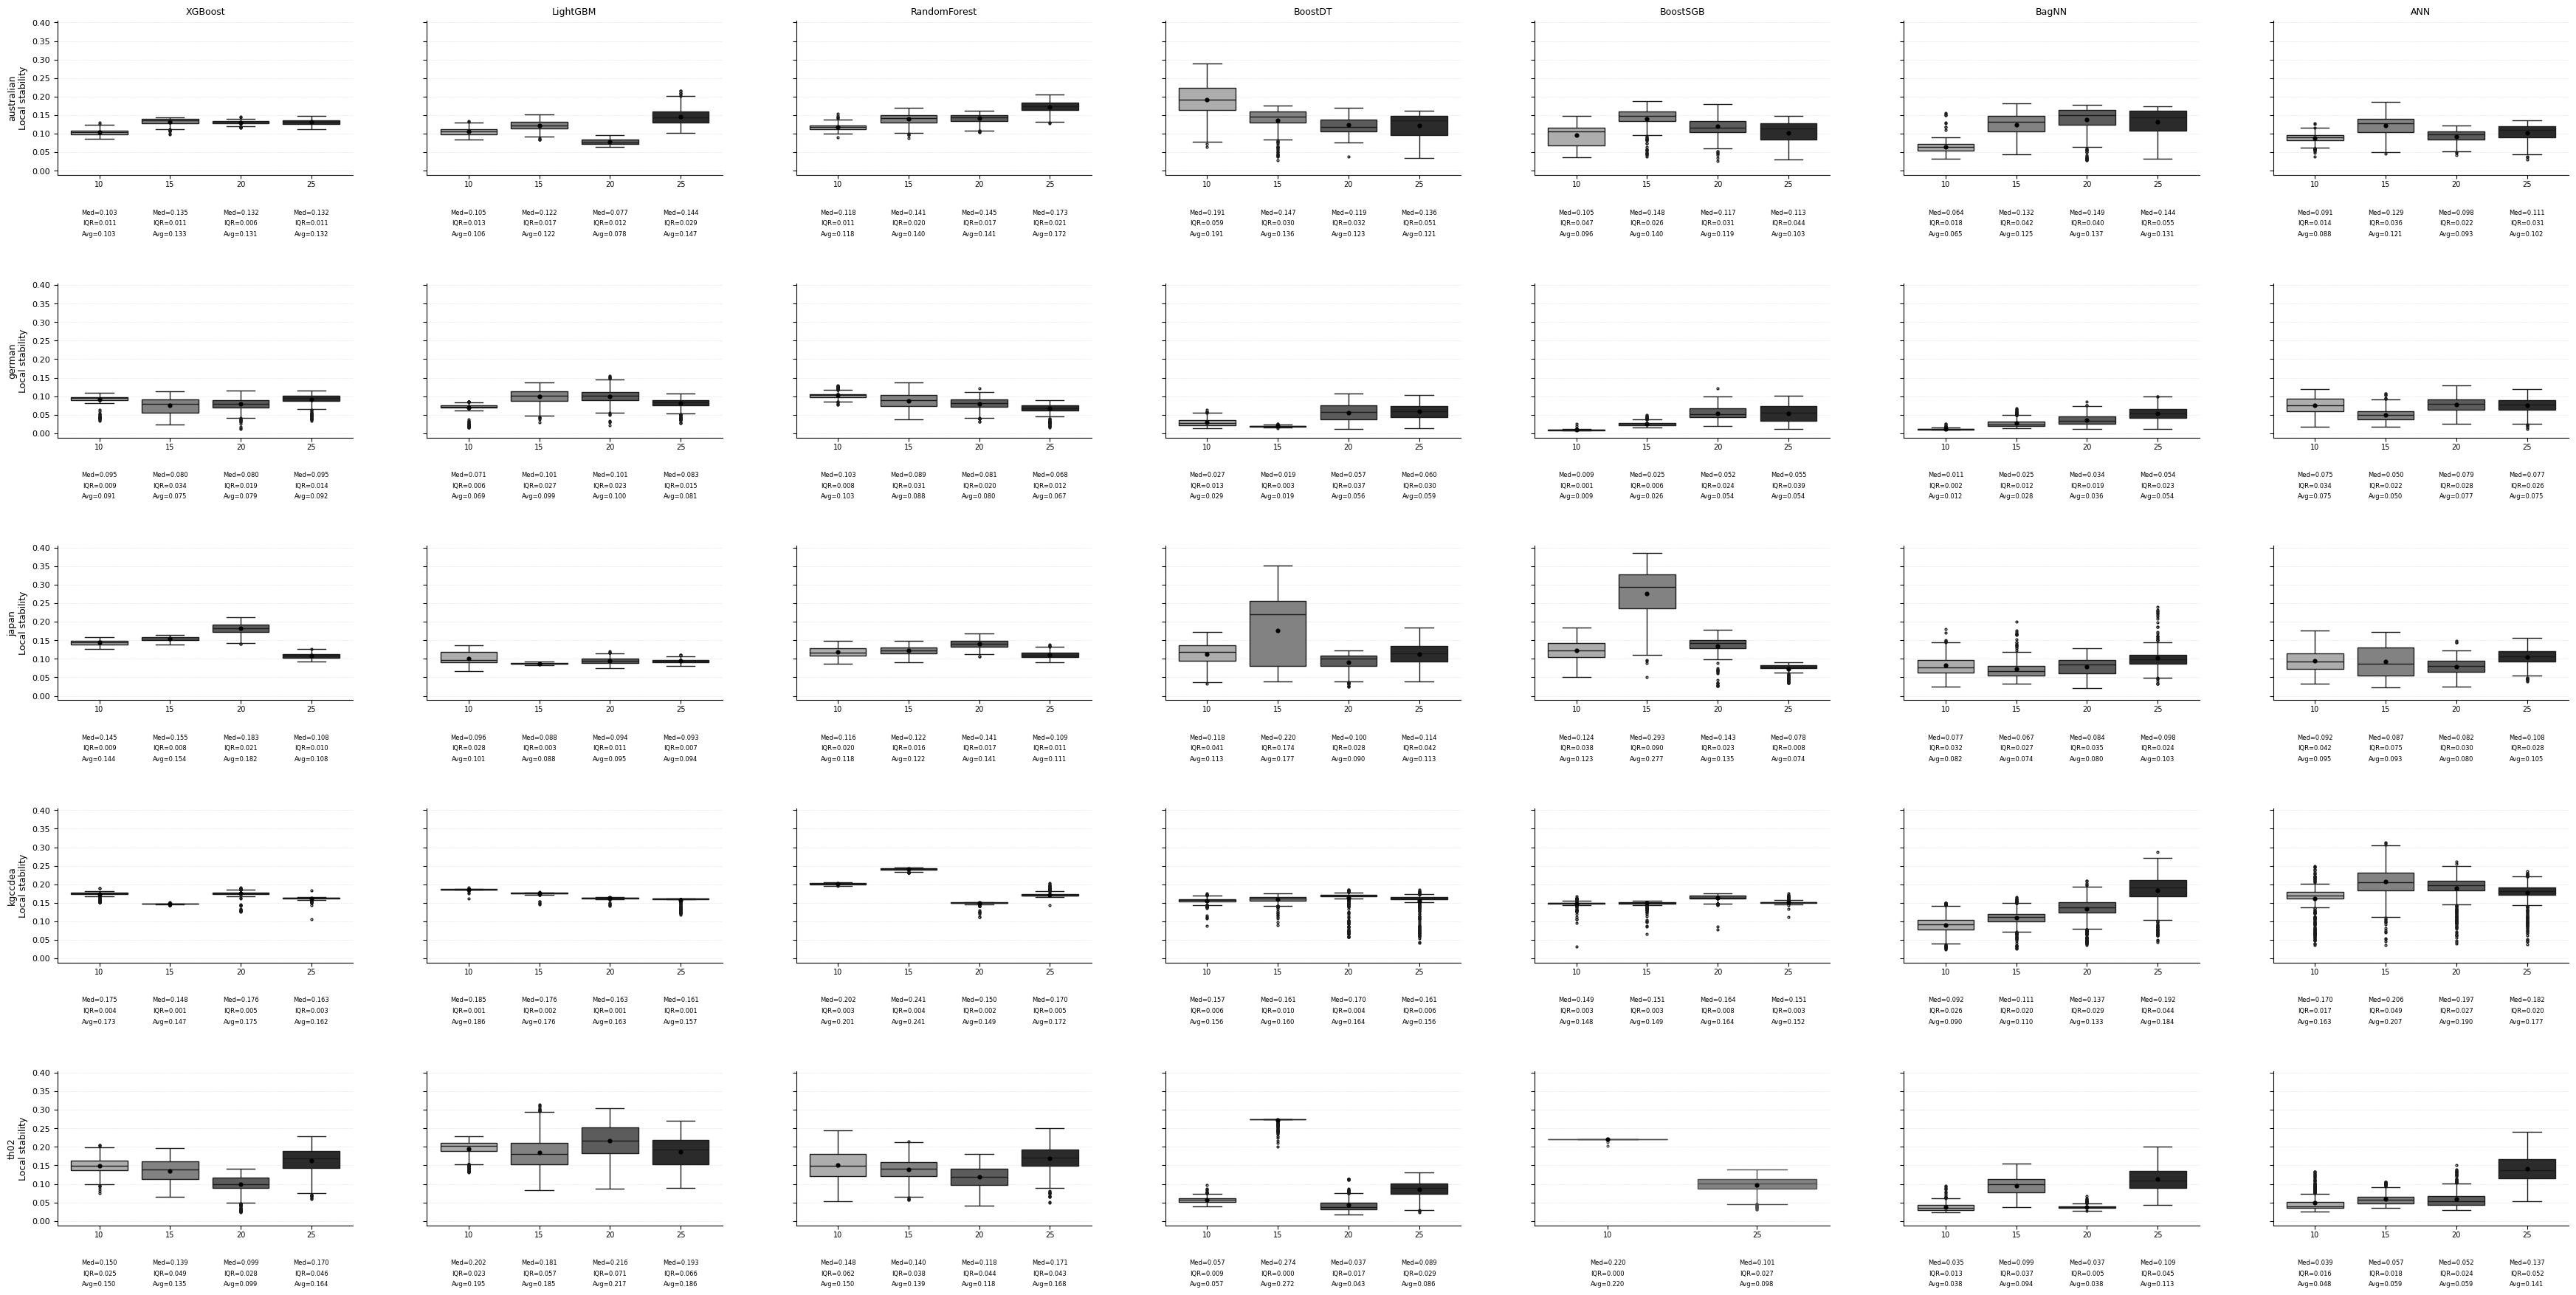

In [4]:
import matplotlib.pyplot as plt

fig, axes = plot_imbalance_boxplot_grid(
    df=df_local,
    datasets=datasets_to_run,
    models=model_choices,
    metric="rankstab_local_weight",
    ylabel="Local stability",
    xlabel="",
    imbalance_order=imbalance_levels,
    suptitle=f""
)

plt.show()


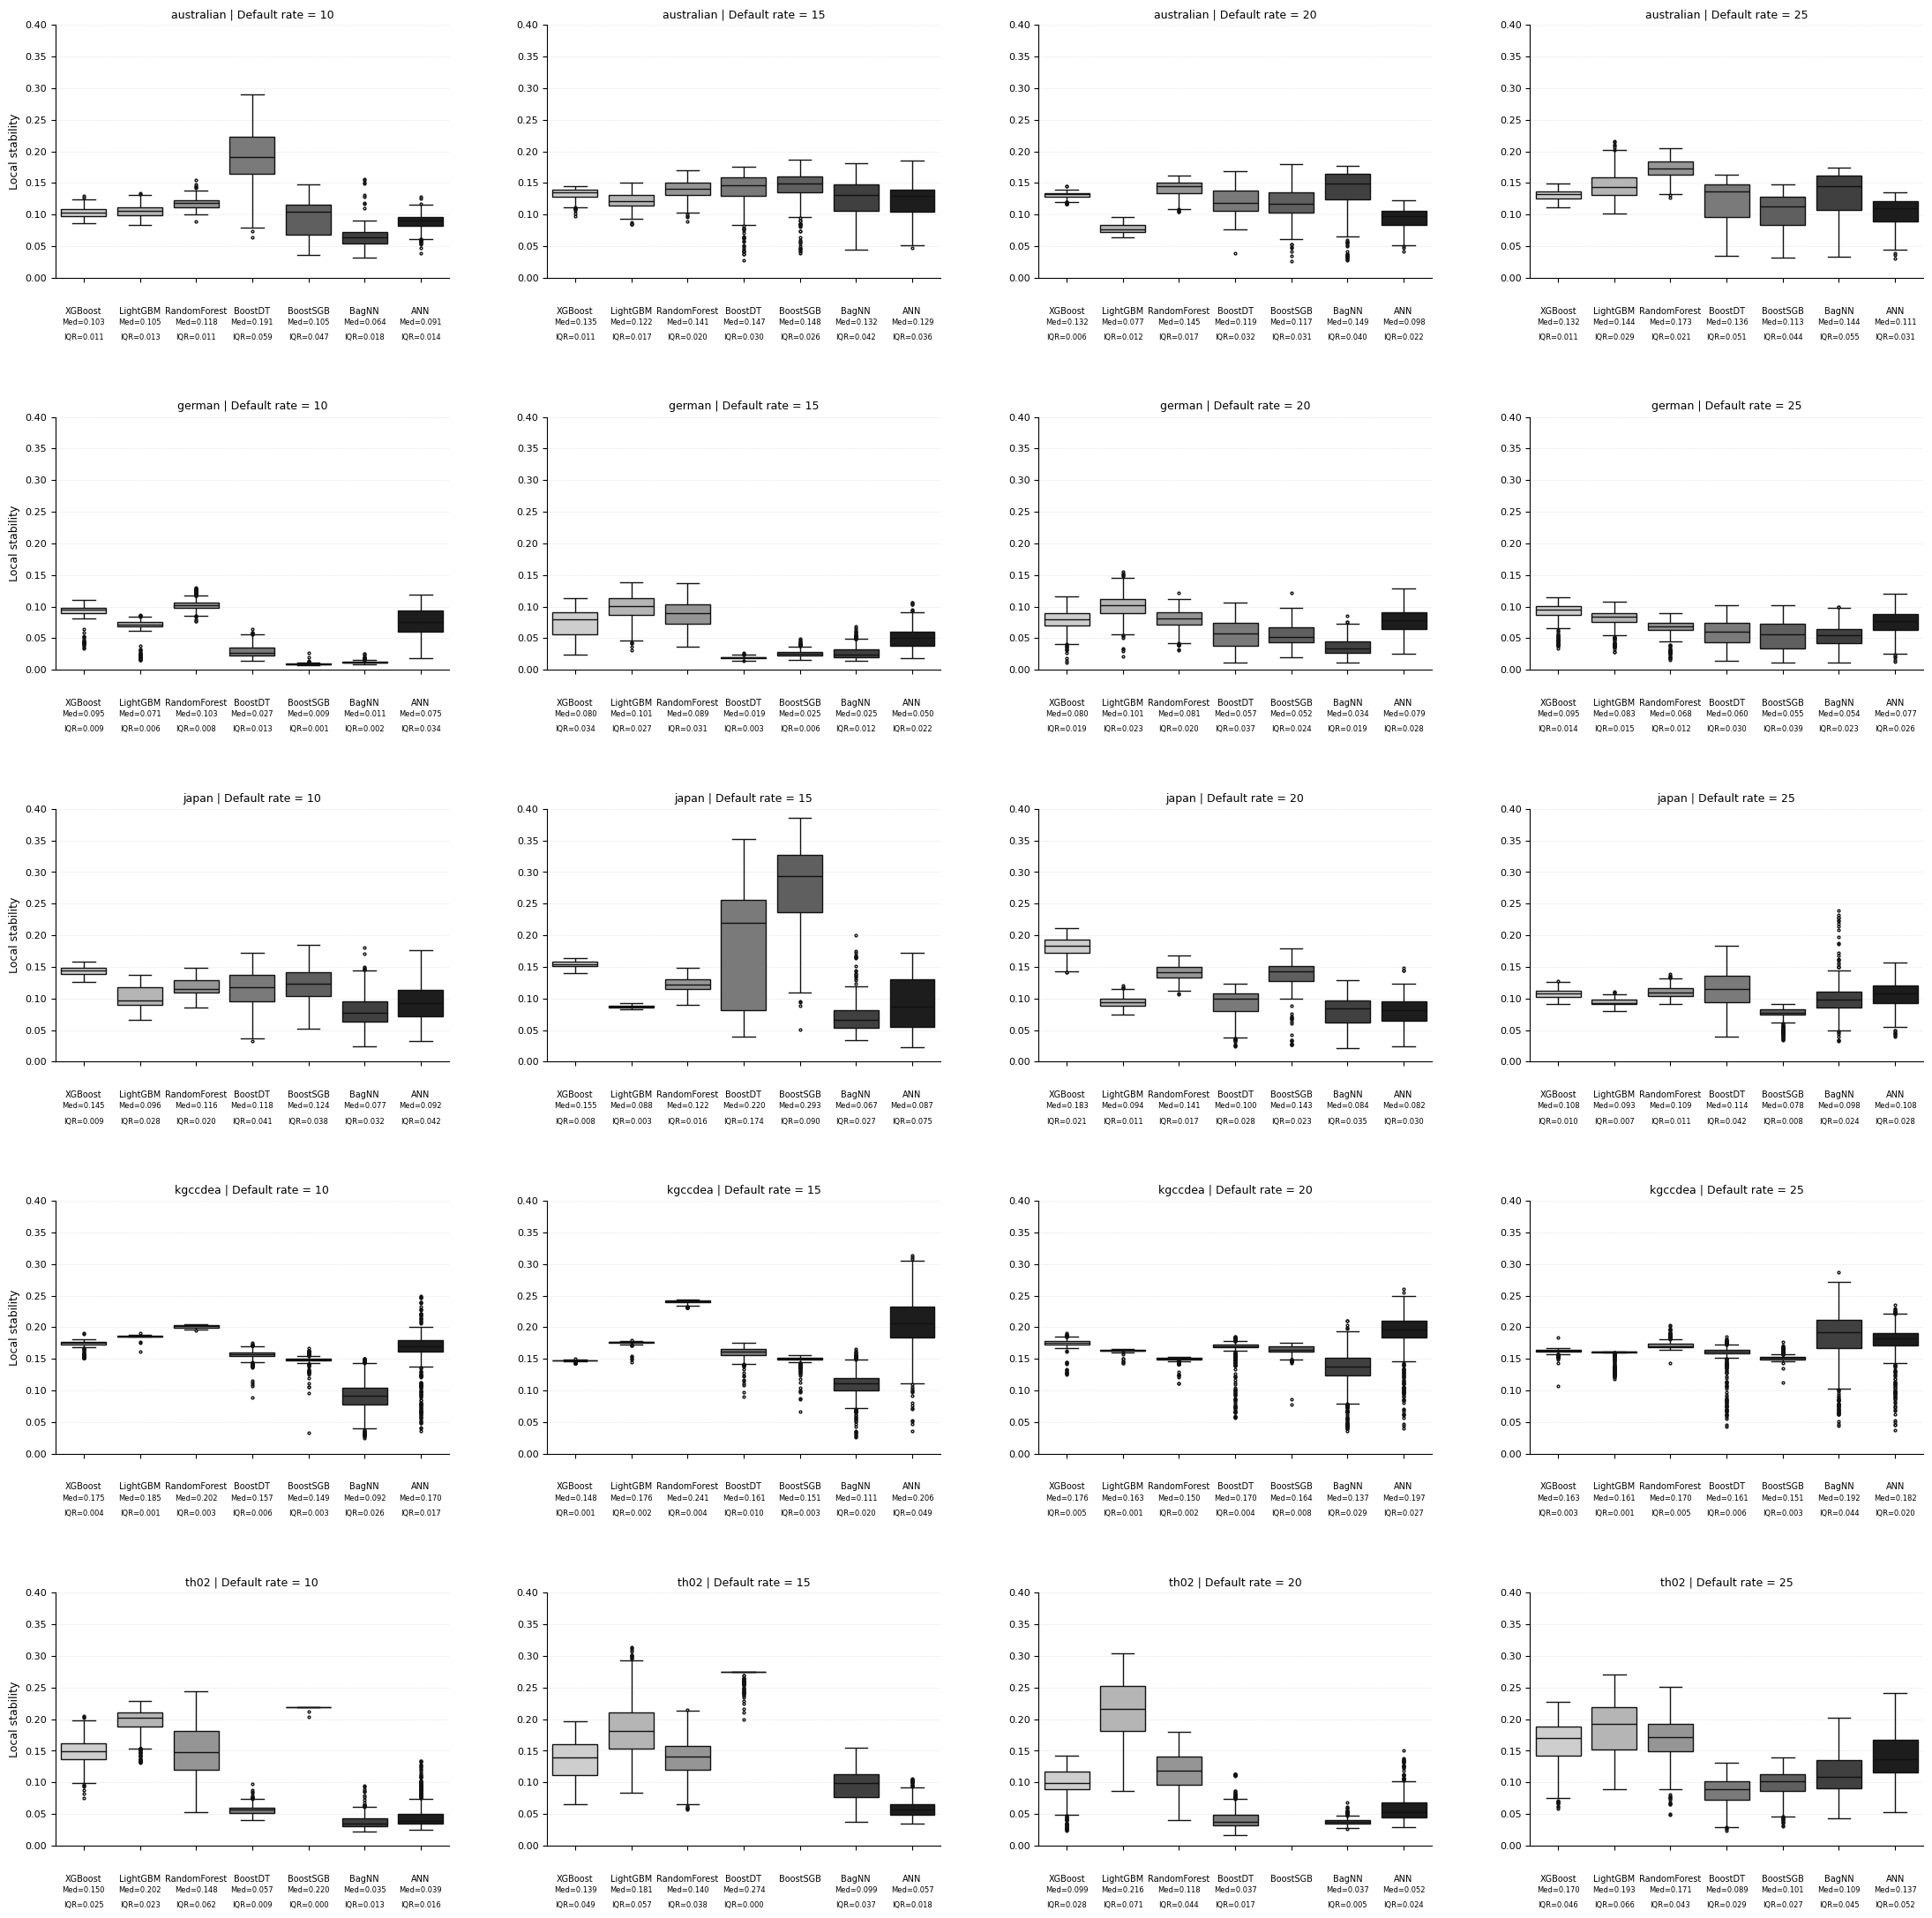

In [7]:
fig, axes = plot_models_by_imbalance(
    df=df_local,
    datasets=datasets_to_run,
    models=model_choices,
    imbalance_levels=imbalance_levels,
    metric="rankstab_local_weight",
    ylabel="Local stability",
    xlabel="",
    suptitle="",
    ylim=(0, 0.4)
)

fig.savefig(
    "figure_1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()